# A distributed representation of temporal context
<p>Ask someone to study a list of words and then recall them in any order. Two regularities appear almost every time. Recall usually begins near the end of the list, which is the <em>recency</em> effect. After one word is recalled, the next word tends to come from a neighboring position, more often the word that followed it than the word that preceded it. This is the <em>contiguity</em> effect, and its forward bias is called <em>asymmetry</em>.</p>
<p>Both effects survive when every word is separated by sixteen seconds of demanding arithmetic. A short-term buffer cannot hold the words across such delays, so something else must carry information about when each word was studied.</p>
<p>Howard and Kahana (2002) proposed that this information is carried by a slowly changing state of <em>temporal context</em>. Each studied word is associated with the context present when it appeared. At test, the current context serves as a retrieval cue, which favors recent words. Recalling a word brings back part of the context in which it was studied, which favors its neighbors.</p>
<p>What changes context in this model is not random noise. Each word retrieves the context it has been associated with, and that retrieved context is blended into the current state. Because a word's prior context enters only the states that follow it, the reinstated cue points forward in time. The temporal context model (TCM) therefore explains recency, contiguity, and asymmetry with one mechanism.</p>

## Tutorial objectives

This tutorial follows the model from its equations to the free recall data it was built to explain. We first define the two measures of recall, then build the context vector one equation at a time, observe how a recalled word reinstates an asymmetric cue, and finally reproduce the model predictions in Figures 7 and 8 of the paper.

Each section pairs an explanation with a short calculation and an experiment. The teaching sequence follows the pattern of [Neuromatch tutorials](https://compneuro.neuromatch.io/tutorials/W1D5_DeepLearning/student/W1D5_Tutorial1.html). It is an independent paper reproduction, not an official Neuromatch tutorial.

## Setup

The setup cell locates a local checkout or downloads the public repository in Colab. Dependencies are installed only when missing. Every cell runs on a CPU within seconds.

In [1]:
# @title Environment and repository
import importlib.util, subprocess, sys
from pathlib import Path
packages = {'numpy':'numpy', 'scipy':'scipy', 'torch':'torch', 'matplotlib':'matplotlib',
            'pandas':'pandas', 'ipywidgets':'ipywidgets'}
missing = [package for module, package in packages.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p/'notebooks/tcm2002/tcm.py').is_file()), None)
if ROOT is None:
    ROOT = Path.cwd()/'papers'
    if not (ROOT/'notebooks/tcm2002/tcm.py').is_file():
        if ROOT.exists():
            raise RuntimeError('The papers directory exists but is not this repository.')
        subprocess.check_call(['git', 'clone', '--depth', '1',
                              'https://github.com/h4ch1m1/complementary-learning-systems.git', str(ROOT)])
sys.path.insert(0, str(ROOT/'notebooks/tcm2002'))
import numpy as np
import torch
import pandas as pd
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display
import tcm
import fit as tcm_fit
from tcm import (Parameters, TemporalContextModel, study_list, study_sequence,
                 transition_distribution, expected_lag_crp, sample_first_two, empirical_first_two)
try:
    from google.colab import output
    output.enable_custom_widget_manager()
except ImportError:
    pass
torch.set_num_threads(1)
plt.rcParams.update({'figure.dpi':110, 'axes.spines.top':False, 'axes.spines.right':False})
PAPER = Parameters(beta=.402, gamma=1., tau=.247, distractor_duration=7.24)
paper_points = pd.read_csv(ROOT/'data/tcm2002/paper_model_points.csv')
print(PAPER)

Parameters(beta=0.402, gamma=1.0, tau=0.247, distractor_duration=7.24)


In [2]:
# @title Plotting helpers
BLUE, ORANGE, GREY = '#3675a8', '#d18538', '#8a8f94'
TITLES = {'immediate':'Immediate', 'delayed':'Delayed', 'continuous':'Continuous distractor'}
LAGS = np.array([x for x in range(-5, 6) if x])

def predict(condition, params=PAPER):
    model, _ = study_list(condition, params)
    first, second = transition_distribution(model, suppress_repeats=True)
    lags, crp, _, _ = expected_lag_crp(first, second)
    return first.numpy(), {int(l): float(c) for l, c in zip(lags, crp)}

def paper_curve(condition, measure):
    rows = paper_points[(paper_points.condition == condition) & (paper_points.measure == measure)]
    return rows.x.to_numpy(), rows.value.to_numpy()

def plot_pfr(ax, condition, pfr, label='TCM', color=BLUE, paper=True):
    if paper:
        x, y = paper_curve(condition, 'pfr')
        ax.plot(x, y, 's', color=GREY, ms=5, label='Paper Fig. 7 model')
    ax.plot(range(1, 13), pfr, 'o-', color=color, ms=4, label=label)
    ax.set(title=TITLES[condition], xlabel='Serial position', xticks=[1, 3, 6, 9, 12], ylim=(0, .85))

def plot_crp(ax, condition, crp, label='TCM', color=BLUE, paper=True):
    for side in (LAGS < 0, LAGS > 0):
        lags = LAGS[side]
        if paper:
            x, y = paper_curve(condition, 'crp')
            keep = np.isin(x, lags)
            ax.plot(x[keep], y[keep], 's-', color=GREY, ms=5, lw=.8,
                    label='Paper Fig. 8 model' if lags[0] > 0 else None)
        ax.plot(lags, [crp[int(l)] for l in lags], 'o-', color=color, ms=4,
                label=label if lags[0] > 0 else None)
    ax.set(title=TITLES[condition], xlabel='Lag', xticks=[-5, -3, -1, 1, 3, 5], ylim=(0, .45))

## 1. Two measures of free recall

In the experiments modeled here, 12 nouns are shown one at a time and then recalled in any order. Two summaries of the recall sequence isolate the effects of interest.

<table><thead><tr><th>Measure</th><th>Question</th><th>Effect</th></tr></thead><tbody>
<tr><td>Probability of first recall (PFR)</td><td>From which serial position does recall begin?</td><td>Recency</td></tr>
<tr><td>Conditional response probability (lag-CRP)</td><td>After recalling position <em>i</em>, how likely is position <em>i</em> + lag next?</td><td>Contiguity and asymmetry</td></tr>
</tbody></table>

The lag-CRP divides the number of transitions of each lag by the number of times that lag was possible. Starting from position 12, a lag of +1 is impossible, so it is not counted against the subject. Here, as in Figure 8, only the transition from the first to the second recall is analyzed.

### Counting transitions by hand

Four short recall sequences are scored below. Each row gives the serial positions of the first two words recalled.

In [3]:
example = torch.tensor([[12, 11], [11, 12], [10, 11], [6, 2]]) - 1
pfr, lags, crp, counts, opportunities = empirical_first_two(example, 12)
pd.DataFrame({'lag':lags.numpy(), 'transitions':counts.numpy(),
              'opportunities':opportunities.numpy(), 'CRP':crp.numpy().round(3)}).query('-4 <= lag <= 4')

,lag,transitions,opportunities,CRP
7,-4,1,4,0.250
8,-3,0,4,0.000
9,-2,0,4,0.000
10,-1,1,4,0.250
11,1,2,3,0.667
12,2,0,2,0.000
13,3,0,1,0.000
14,4,0,1,0.000


**Checkpoint.** Lag +1 occurred twice in four lists, but only three of the four first recalls had a successor in the list, so CRP(+1) = 2/3. Lag −4 occurred once and was possible four times.

## 2. Context drifts as items are studied

Each item is a vector **f** in an item space *F*; context is a unit vector **t** in a separate space *T*. When an item is presented it retrieves an input to context through an item-to-context matrix, and the input is blended into the current state:

<div class="equation">t<sup>IN</sup><sub>i</sub> = M<sup>FT</sup>f<sub>i</sub>, &nbsp; t<sub>i</sub> = ρ<sub>i</sub>t<sub>i−1</sub> + βt<sup>IN</sup><sub>i</sub></div>

β sets how much new input enters at each step. ρ<sub>i</sub> is not a free parameter: it is chosen at every step so that ‖t<sub>i</sub>‖ = 1, which gives

<div class="equation">ρ<sub>i</sub> = √(1 + β²[(t<sub>i−1</sub>·t<sup>IN</sup><sub>i</sub>)² − 1]) − β(t<sub>i−1</sub>·t<sup>IN</sup><sub>i</sub>)</div>

At the start of an experiment each word retrieves its own preexperimental context. For unrelated words these inputs are orthogonal, so t<sub>i−1</sub>·t<sup>IN</sup><sub>i</sub> = 0 and ρ = √(1 − β²).

### One presentation

The calculation below presents the first item and compares a hand calculation with the model.

In [4]:
model = TemporalContextModel(12, params=PAPER)
previous = model.context.clone()
incoming = model.retrieve_context(0)
dot = float(previous @ incoming)
beta = PAPER.beta
rho = np.sqrt(1 + beta**2*(dot**2 - 1)) - beta*dot
trace = model.present(0)
assert np.isclose(rho, float(trace['rho']))
assert torch.allclose(model.context, rho*previous + beta*incoming)
pd.DataFrame({'quantity':['t(i-1) · t_IN', 'rho', 'beta', '||t(i)||', 't(i) · t(i-1)'],
              'value':[dot, rho, beta, float(model.context.norm()), float(model.context @ previous)]})

,quantity,value
0,t(i-1) · t_IN,0.00000
1,rho,0.91564
2,beta,0.40200
3,||t(i)||,1.00000
4,t(i) · t(i-1),0.91564


### The proximity relationship

After a list of unrelated words, the similarity between the contexts of positions *i* and *j* is ρ<sup>|i−j|</sup>. Nearby positions share context, distant positions share little. Change β to see how fast context drifts.

In [5]:
def proximity(beta=.402):
    params = Parameters(beta=beta, gamma=1., tau=PAPER.tau, distractor_duration=PAPER.distractor_duration)
    _, history = study_list('immediate', params)
    similarity = (history @ history.T).numpy()
    fig, ax = plt.subplots(1, 2, figsize=(9, 3.6), gridspec_kw={'width_ratios':[1, 1.3]})
    image = ax[0].imshow(similarity, cmap='Blues', vmin=0, vmax=1)
    ax[0].set(title='t(i) · t(j)', xlabel='Serial position j', ylabel='Serial position i',
              xticks=[0, 5, 11], xticklabels=[1, 6, 12], yticks=[0, 5, 11], yticklabels=[1, 6, 12])
    fig.colorbar(image, ax=ax[0], fraction=.046)
    rho = np.sqrt(1 - beta**2)
    ax[1].plot(range(1, 13), similarity[-1], 'o', color=BLUE, label='Model')
    ax[1].plot(range(1, 13), rho**np.arange(11, -1, -1), color=GREY, label='ρ^(12−i)')
    ax[1].set(title='Similarity to the end-of-list context', xlabel='Serial position i', ylim=(0, 1.05))
    ax[1].legend(frameon=False)
    plt.tight_layout(); plt.show()

widgets.interact(proximity, beta=widgets.FloatSlider(min=.1, max=.9, step=.01, value=.402,
                                                     description='β', continuous_update=False));

interactive(children=(FloatSlider(value=0.402, continuous_update=False, description='β', max=0.9, min=0.1, ste…

**Checkpoint.** Nothing in the drift equation refers to clock time. When no item is presented, t<sup>IN</sup> = 0 and context does not change. Context changes because new information arrives, not because time passes.

## 3. Context as a retrieval cue

A context-to-item matrix stores each item with the context present when it was studied:

<div class="equation">M<sup>TF</sup> = Σ<sub>i</sub> f<sub>i</sub>t<sub>i</sub><sup>⊤</sup>, &nbsp; a<sub>i</sub> = f<sub>i</sub> · M<sup>TF</sup>t = t<sub>i</sub> · t</div>

The activation a<sub>i</sub> of an item is simply the similarity between its study context and the cue. Activations are turned into recall probabilities with a competitive rule (Eq. 14):

<div class="equation">P(f<sub>i</sub>) = exp(2a<sub>i</sub>/τ) / Σ<sub>j</sub> exp(2a<sub>j</sub>/τ)</div>

Smaller τ makes the competition sharper. Because only relative activations matter, recency persists whenever the end of the list is relatively closer to the test context than earlier positions, whatever the absolute delay.

In [6]:
def competition(tau=.247):
    model, _ = study_list('immediate', PAPER)
    activation = model.activations().numpy()
    probability = torch.softmax(torch.from_numpy(2*activation/tau), 0).numpy()
    fig, ax = plt.subplots(1, 2, figsize=(9, 3.2))
    ax[0].bar(range(1, 13), activation, color=GREY)
    ax[0].set(title='Activation a(i) = t(i) · t(test)', xlabel='Serial position', ylim=(0, 1.05))
    ax[1].bar(range(1, 13), probability, color=BLUE)
    ax[1].set(title=f'First-recall probability, τ = {tau:.3f}', xlabel='Serial position', ylim=(0, 1))
    plt.tight_layout(); plt.show()

widgets.interact(competition, tau=widgets.FloatSlider(min=.05, max=1., step=.01, value=.247,
                                                      description='τ', continuous_update=False));

interactive(children=(FloatSlider(value=0.247, continuous_update=False, description='τ', max=1.0, min=0.05, st…

## 4. A recalled item reinstates an asymmetric cue

When an item is repeated, or recalled, it retrieves a mixture of two contexts. One is its preexperimental context t<sup>IN</sup><sub>i</sub>, the input it delivered at study. The other is the context t<sub>i</sub> in which it was just studied. The item-to-context matrix learns this mixture:

<div class="equation">M<sup>FT</sup><sub>i+1</sub> = M<sup>FT</sup><sub>i</sub>P̃<sub>f<sub>i</sub></sub> + A<sub>i</sub>M<sup>FT</sup><sub>i</sub>P<sub>f<sub>i</sub></sub> + B<sub>i</sub>t<sub>i</sub>f<sub>i</sub><sup>⊤</sup></div>

P<sub>f</sub> projects onto the item, so only that item's association changes. The ratio γ = A/B weighs preexperimental against newly learned context, and B<sub>i</sub> = [γ² + 2γ(t<sup>IN</sup><sub>i</sub>·t<sub>i</sub>) + 1]<sup>−1/2</sup> keeps the retrieved vector at unit length.

The two parts differ in their temporal profile. The study context t<sub>i</sub> resembles states on both sides of position *i*. The preexperimental context entered t<sub>i</sub> and every later state, but none of the earlier ones, so it only points forward.

In [7]:
def cue_components(gamma=1., position=6):
    params = Parameters(beta=PAPER.beta, gamma=gamma, tau=PAPER.tau, distractor_duration=PAPER.distractor_duration)
    model, history = study_list('immediate', params)
    i = position - 1
    old = torch.zeros_like(model.context); old[i] = 1
    lags = np.arange(12) - i
    fig, ax = plt.subplots(figsize=(7.5, 3.6))
    for cue, label, color in [(history[i], 'Study context t(i)', GREY),
                              (old, 'Preexperimental context t_IN(i)', ORANGE),
                              (model.retrieve_context(i), f'Retrieved mixture, γ = {gamma:.1f}', BLUE)]:
        ax.plot(lags, (history @ cue).numpy(), 'o-', ms=4, color=color, label=label)
    ax.axvline(0, color='#cccccc', lw=.8)
    ax.set(xlabel='Lag from the recalled item', ylabel='Similarity to study context', ylim=(-.02, 1.05))
    ax.legend(frameon=False, fontsize=9); plt.tight_layout(); plt.show()

widgets.interact(cue_components,
    gamma=widgets.FloatSlider(min=0, max=4, step=.1, value=1., description='γ', continuous_update=False),
    position=widgets.IntSlider(min=2, max=11, value=6, description='Item', continuous_update=False));

interactive(children=(FloatSlider(value=1.0, continuous_update=False, description='γ', max=4.0), IntSlider(val…

**Checkpoint.** With γ = 0 the retrieved cue is the study context alone and the curve is symmetric. As γ grows, the forward side rises above the backward side. The paper fixes γ = 1, so asymmetry needs no extra parameter: it follows from what context the item retrieves.

### Excluding repetitions

After a recall the model updates context and both matrices in the same order as during study: retrieve, integrate, then learn. Learning stores the current context with the recalled item again, which makes that item the strongest candidate for the next response.

In [8]:
model, _ = study_list('delayed', PAPER)
first, raw = transition_distribution(model)
_, excluded = transition_distribution(model, suppress_repeats=True)
print(f'Probability that the second response repeats the first: {float((first*raw.diag()).sum()):.3f}')
print(f'After excluding the recalled item:                       {float((first*excluded.diag()).sum()):.3f}')

Probability that the second response repeats the first: 0.999
After excluding the recalled item:                       0.000


Subjects rarely repeat words, and the lag-CRP counts only transitions to words not yet recalled. The comparisons below therefore remove recalled items from the choice set. For the first transition this is the same as renormalizing the raw probabilities over non-repeated items.

## 5. Recency across time scales

Howard and Kahana (1999) tested three conditions. In delayed recall, 16 s of arithmetic followed the list. In continuous-distractor recall, 16 s of arithmetic also followed every word. The model represents each distractor period as an interval of effective length *d*, during which context drifts as though *d* new unrelated items had been studied. The fit gave *d* = 7.24 rather than the 13 items that 16 s would hold at the study rate, consistent with arithmetic problems resembling each other and causing less drift.

<table><thead><tr><th>Condition</th><th>Sequence (D = one distractor interval)</th><th>Last item to test</th><th>Between items</th></tr></thead><tbody>
<tr><td>Immediate</td><td>f1 f2 … f12 → test</td><td>0</td><td>1</td></tr>
<tr><td>Delayed</td><td>f1 f2 … f12 D → test</td><td><em>d</em></td><td>1</td></tr>
<tr><td>Continuous distractor</td><td>f1 D f2 D … f12 D D → test</td><td>2<em>d</em></td><td><em>d</em> + 1</td></tr>
</tbody></table>

In the continuous condition the last word is followed by its own interpresentation distractor and then by the retention interval.

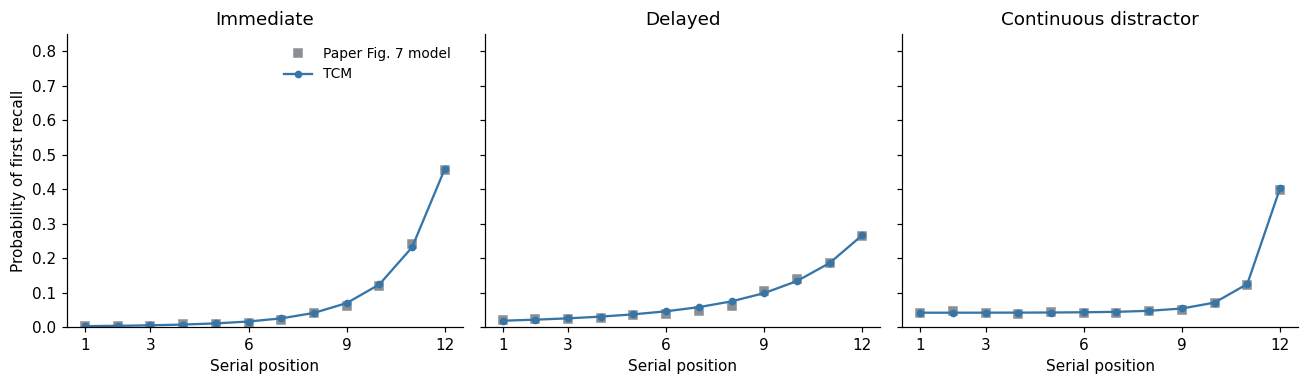

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), sharey=True)
for ax, condition in zip(axes, tcm.CONDITIONS):
    pfr, _ = predict(condition)
    plot_pfr(ax, condition, pfr)
axes[0].set_ylabel('Probability of first recall'); axes[0].legend(frameon=False, fontsize=9)
plt.tight_layout(); plt.show()

Grey squares are the model predictions read from Figure 7 of the paper; blue circles are computed here with the published parameters β = 0.402, τ = 0.247, γ = 1, and *d* = 7.24. The curves are exact probabilities rather than 3000 simulated lists, so the small scatter of the grey squares around them is sampling noise in the original figure.

### Where the distractors go

The placement of distractor intervals changes the predictions. Choose a sequence to see how the end-of-list recency in the continuous condition depends on it.

In [10]:
SEQUENCES = {
    'Paper: f D … f D D':' '.join(['f D']*12 + ['D']),
    'Retention interval only after the last item: f D … D f D':' '.join(['f D']*11 + ['f', 'D']),
    'Distractors between items only: f D … D f':' '.join(['f D']*11 + ['f']),
}
def placement(sequence='Paper: f D … f D D'):
    model, _ = study_sequence(SEQUENCES[sequence], PAPER)
    first, second = transition_distribution(model, suppress_repeats=True)
    lags, crp, _, _ = expected_lag_crp(first, second)
    fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
    plot_pfr(ax[0], 'continuous', first.numpy())
    plot_crp(ax[1], 'continuous', {int(l): float(c) for l, c in zip(lags, crp)})
    ax[0].legend(frameon=False, fontsize=9); ax[1].legend(frameon=False, fontsize=9, loc='upper left')
    plt.tight_layout(); plt.show()
    print(f'Last item first: {float(first[-1]):.3f}   CRP(-1) = {float(crp[lags == -1]):.3f}   CRP(+1) = {float(crp[lags == 1]):.3f}')

widgets.interact(placement, sequence=widgets.Dropdown(options=list(SEQUENCES), description='Sequence',
                                                      layout=widgets.Layout(width='480px')));

interactive(children=(Dropdown(description='Sequence', layout=Layout(width='480px'), options=('Paper: f D … f …

**Checkpoint.** If the last word is followed only by the retention interval, it is *d* from the test but its neighbor is 2*d* + 1 away. Its activation dominates the competition and the model predicts that recall begins with it on almost 80% of lists. Adding the final distractor moves all list items equally far back, reducing every activation by the same factor ρ<sup>d</sup>, and the competition becomes as balanced as in the paper.

## 6. Contiguity across time scales

The lag-CRP is computed from the context that follows the first recall. The recalled word reinstates its mixture of preexperimental and study context, the cue moves toward the word's original neighborhood, and the next response is selected with the same competitive rule.

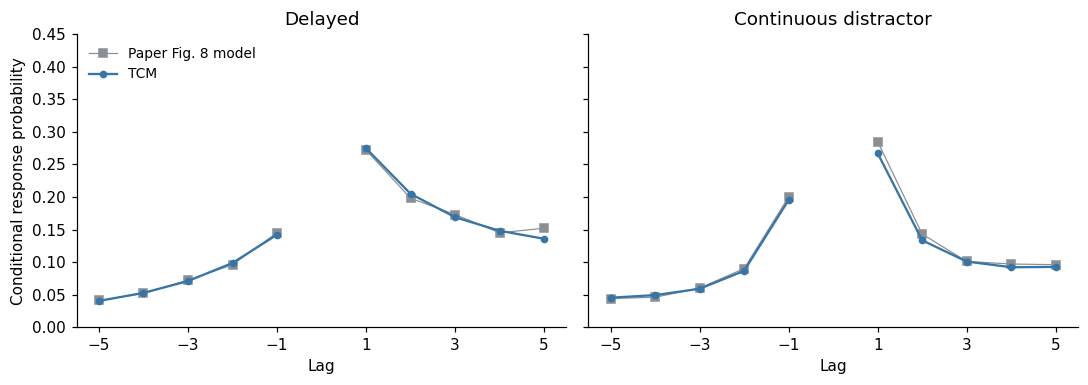

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
for ax, condition in zip(axes, ['delayed', 'continuous']):
    _, crp = predict(condition)
    plot_crp(ax, condition, crp)
axes[0].set_ylabel('Conditional response probability'); axes[0].legend(frameon=False, fontsize=9, loc='upper left')
plt.tight_layout(); plt.show()

Both conditions show the peaked, asymmetric shape. The spacing between neighbors grows from 1 to *d* + 1 in the continuous condition, yet the curve keeps its shape, because recall depends on the relative similarity of nearby and distant contexts.

In [12]:
rows = []
for condition in tcm.CONDITIONS:
    pfr, crp = predict(condition)
    for _, row in paper_points[paper_points.condition == condition].iterrows():
        value = pfr[row.x - 1] if row.measure == 'pfr' else crp[row.x]
        rows.append({'condition':condition, 'measure':row.measure.upper(), 'difference':value - row.value})
table = pd.DataFrame(rows).groupby(['condition', 'measure'], sort=False).difference
pd.DataFrame({'points':table.size(), 'RMSE':table.apply(lambda d: np.sqrt(np.mean(d**2))),
              'largest difference':table.apply(lambda d: d.abs().max())}).round(4)

points    RMSE  largest difference
condition  measure                                    
immediate  PFR          12  0.0042              0.0081
delayed    PFR          12  0.0063              0.0130
           CRP          10  0.0060              0.0162
continuous PFR          12  0.0036              0.0059
           CRP          10  0.0070              0.0179

### Exploring the parameters

All five curves share three parameters. β sets the rate of drift, τ the sharpness of the competition, and *d* the length of a distractor interval. Change them to see which curves each parameter controls.

In [13]:
def explore(beta=.402, tau=.247, d=7.24):
    params = Parameters(beta=beta, gamma=1., tau=tau, distractor_duration=d)
    fig, axes = plt.subplots(2, 3, figsize=(12, 6.4))
    for k, condition in enumerate(tcm.CONDITIONS):
        pfr, crp = predict(condition, params)
        plot_pfr(axes[0, k], condition, pfr)
        if k:
            plot_crp(axes[1, k], condition, crp)
    axes[1, 0].axis('off')
    axes[0, 0].legend(frameon=False, fontsize=9)
    axes[0, 0].set_ylabel('Probability of first recall'); axes[1, 1].set_ylabel('Conditional response probability')
    plt.tight_layout(); plt.show()

widgets.interact(explore,
    beta=widgets.FloatSlider(min=.2, max=.7, step=.01, value=.402, description='β', continuous_update=False),
    tau=widgets.FloatSlider(min=.1, max=.6, step=.005, value=.247, description='τ', continuous_update=False),
    d=widgets.FloatSlider(min=0, max=15, step=.1, value=7.24, description='d', continuous_update=False));

interactive(children=(FloatSlider(value=0.402, continuous_update=False, description='β', max=0.7, min=0.2, ste…

**Checkpoint.** *d* has no effect on immediate recall. In the delayed condition it only lowers every activation by the same factor, which flattens recency. In the continuous condition it also spaces the items apart, which steepens recency and sharpens the lag-CRP. The same *d* must satisfy both conditions.

## 7. Comparing with the behavioral data

The paper estimated β, τ, and *d* by fitting the PFR of the immediate condition of Experiment 1 together with the PFR and first-transition lag-CRP of the delayed and continuous-distractor conditions of Experiment 2 of Howard and Kahana (1999). The raw recall data are distributed through the [Computational Memory Lab data archive](https://memory.psych.upenn.edu/Data_Archive).

`fit.observations_from_recalls` converts a recall matrix into subject-averaged PFR and lag-CRP points with their squared standard errors. Each row of the matrix is one list; entries are the serial positions recalled in output order, with 0 or a negative number for no response or an intrusion. The cell below demonstrates the conversion on lists simulated from the model, sixteen simulated subjects per condition, each studying the same number of lists.

In [14]:
def simulate_recalls(condition, subjects=16, lists_per_subject=50, seed=1999):
    model, _ = study_list(condition, PAPER)
    first, second = transition_distribution(model, suppress_repeats=True)
    pairs = sample_first_two(first, second, subjects*lists_per_subject, seed).numpy() + 1
    recalls = np.hstack([pairs, np.zeros((len(pairs), 10), dtype=int)])
    return recalls, np.repeat(np.arange(subjects), lists_per_subject)

simulated = []
for k, condition in enumerate(tcm.CONDITIONS):
    recalls, subjects = simulate_recalls(condition, seed=1999 + k)
    simulated += tcm_fit.observations_from_recalls(recalls, subjects, condition)
pd.DataFrame([(*key, value, variance) for key, value, variance in simulated],
             columns=['condition', 'measure', 'x', 'value', 'variance']).head(8)

,condition,measure,x,value,variance
0,immediate,pfr,1,0.00250,0.0001
1,immediate,pfr,2,0.01000,0.0001
2,immediate,pfr,3,0.00750,0.0001
3,immediate,pfr,4,0.00625,0.0001
4,immediate,pfr,5,0.00750,0.0001
5,immediate,pfr,6,0.01625,0.0001
6,immediate,pfr,7,0.03250,0.0001
7,immediate,pfr,8,0.03500,0.0001


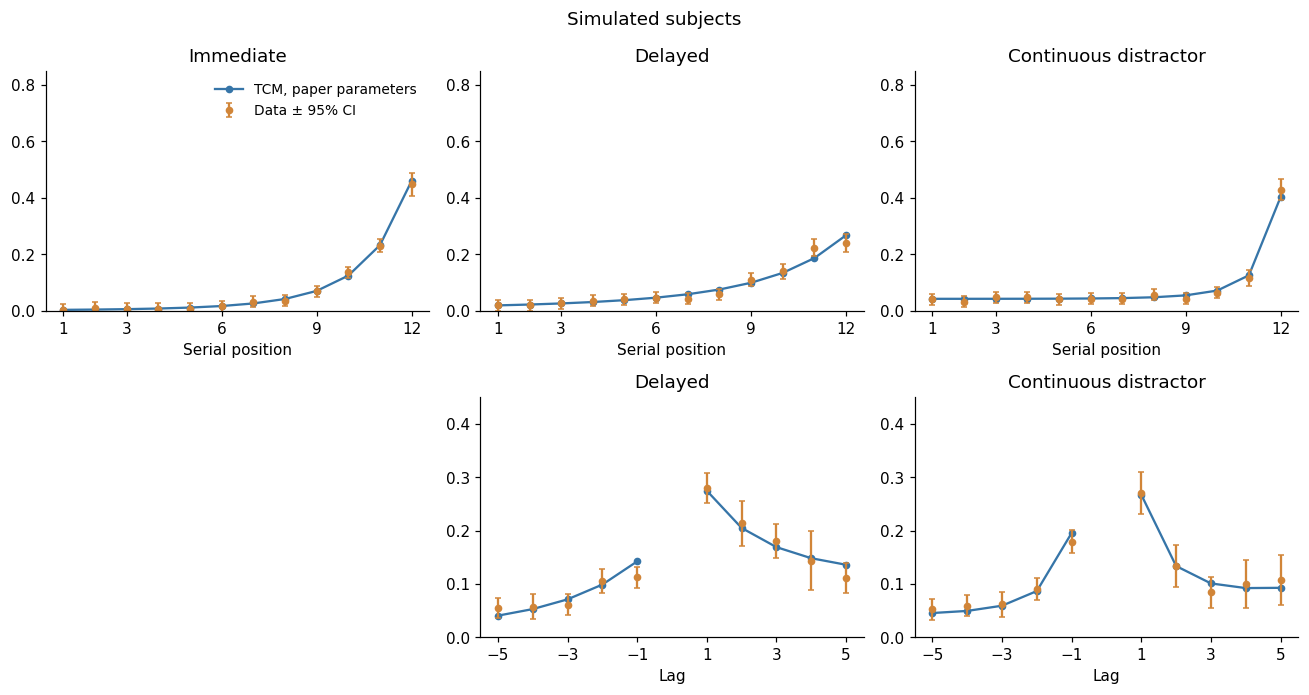

In [15]:
def plot_observations(observed, title):
    lookup = {key:(value, variance) for key, value, variance in observed}
    fig, axes = plt.subplots(2, 3, figsize=(12, 6.4))
    for k, condition in enumerate(tcm.CONDITIONS):
        pfr, crp = predict(condition)
        plot_pfr(axes[0, k], condition, pfr, label='TCM, paper parameters', paper=False)
        points = [(x, *lookup[(condition, 'pfr', x)]) for x in range(1, 13) if (condition, 'pfr', x) in lookup]
        if points:
            x, y, v = map(np.array, zip(*points))
            axes[0, k].errorbar(x, y, 1.96*np.sqrt(v), fmt='o', color=ORANGE, ms=4, capsize=2, label='Data ± 95% CI')
        if k:
            plot_crp(axes[1, k], condition, crp, label='TCM, paper parameters', paper=False)
            points = [(x, *lookup[(condition, 'crp', x)]) for x in LAGS if (condition, 'crp', x) in lookup]
            if points:
                x, y, v = map(np.array, zip(*points))
                axes[1, k].errorbar(x, y, 1.96*np.sqrt(v), fmt='o', color=ORANGE, ms=4, capsize=2)
    axes[1, 0].axis('off'); axes[0, 0].legend(frameon=False, fontsize=9)
    fig.suptitle(title); plt.tight_layout(); plt.show()

plot_observations(simulated, 'Simulated subjects')

### Fitting the archived data

Download the Howard and Kahana (1999) data from the archive and place the files in `data/tcm2002/`. Load each condition into a recall matrix and a subject vector, then set `RUN_DATA_FIT` to fit β, τ, and *d* with the Nelder–Mead simplex method, minimizing the variance-weighted root-mean-squared deviation used in the paper, with γ fixed at 1.

`load_condition` reads a MATLAB file containing a structure with `recalls` and `subject` fields, the layout used by the lab's free recall datasets. Edit the file names and field names to match the downloaded files.

In [16]:
# @title Optional data fit
RUN_DATA_FIT = False # @param {type:"boolean"}
DATA_FILES = {'immediate':'data/tcm2002/immediate.mat',
              'delayed':'data/tcm2002/delayed.mat',
              'continuous':'data/tcm2002/continuous.mat'}
RECALLS_FIELD = 'recalls' # @param {type:"string"}
SUBJECT_FIELD = 'subject' # @param {type:"string"}

def load_condition(path):
    from scipy.io import loadmat
    content = loadmat(ROOT/path, squeeze_me=True, struct_as_record=False)
    record = next((v for v in content.values() if hasattr(v, RECALLS_FIELD)), None)
    source = (lambda name: getattr(record, name)) if record is not None else content.__getitem__
    return np.atleast_2d(source(RECALLS_FIELD)).astype(int), np.ravel(source(SUBJECT_FIELD))

if RUN_DATA_FIT:
    observed = []
    for condition, path in DATA_FILES.items():
        recalls, subjects = load_condition(path)
        observed += tcm_fit.observations_from_recalls(recalls, subjects, condition)
    plot_observations(observed, 'Howard and Kahana (1999)')
    result = tcm_fit.fit(observed)
    print(pd.Series(result['parameters']).round(4).to_string())
    print(f"weighted RMSD = {result['weighted_rmsd']:.4f} after {result['evaluations']} evaluations")
else:
    print('Set RUN_DATA_FIT after placing the archived data in data/tcm2002/.')

Set RUN_DATA_FIT after placing the archived data in data/tcm2002/.


## Resources

- [Original paper](https://doi.org/10.1006/jmps.2001.1388)
- [Author manuscript](https://memory.psych.upenn.edu/files/pubs/HowaKaha02.pdf)
- [Howard and Kahana (1999), source of the data](https://memory.psych.upenn.edu/files/pubs/HowaKaha99.pdf)
- [Computational Memory Lab data archive](https://memory.psych.upenn.edu/Data_Archive)
- [Model code](https://github.com/h4ch1m1/complementary-learning-systems/blob/main/notebooks/tcm2002/tcm.py)